# 实验三 D：利用 AlexNet 进行语音唤醒词识别

使用 Mini Speech Commands 的八类语音命令作为待识别词，将音频转换为对数梅尔频谱图，训练适配单通道输入的 AlexNet。展示波形与频谱、训练曲线、测试混淆矩阵及各类别指标。

数据包含 down、go、left、no、right、stop、up、yes，每类 1000 段音频。按说话人划分训练、验证和测试集，测试集只用于最终评估。本实验是八类短音频的闭集分类，没有未知词和静音类别，不能直接等同于连续音频中的实际唤醒检测。

来源：[TensorFlow 官方音频教程](https://www.tensorflow.org/tutorials/audio/simple_audio)；[Torchvision AlexNet](https://docs.pytorch.org/vision/stable/models/generated/torchvision.models.alexnet.html)。首次运行下载约 182 MB 数据，需要安装 `requirements.txt` 中的依赖。

In [1]:
from pathlib import Path
from urllib.request import urlretrieve
import zipfile
import random
import json
import time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import librosa
from scipy.io import wavfile
from sklearn.model_selection import GroupShuffleSplit
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
import torch
from torch import nn
import torch.nn.functional as F
from torch.utils.data import TensorDataset, DataLoader
from torchvision.models import alexnet

ROOT = Path.cwd()
if ROOT.name != "exp3" and (ROOT / "exp3").is_dir():
    ROOT = ROOT / "exp3"
DATA_DIR = ROOT / "data" / "mini_speech_commands"
CACHE_DIR = ROOT / ".cache" / "exp3D"
RESULT_DIR = ROOT / "results" / "exp3D"
for folder in [DATA_DIR.parent, CACHE_DIR, RESULT_DIR]:
    folder.mkdir(parents=True, exist_ok=True)
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.set_num_threads(min(4, torch.get_num_threads()))
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
if device.type == "cuda":
    torch.cuda.manual_seed_all(SEED)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False
plt.rcParams["font.sans-serif"] = ["Microsoft YaHei", "SimHei", "DejaVu Sans"]
plt.rcParams["axes.unicode_minus"] = False
print("运行设备：", device)

运行设备： cpu


## 1. 数据下载与说话人划分

文件名中 `_nohash_` 之前的部分作为说话人编号。同一说话人的全部录音只能属于一个集合，按约 70% / 15% / 15% 划分。分组后的各类别数量不一定完全相同，下面保存实际样本清单及分布。

In [2]:
archive = ROOT / ".cache" / "mini_speech_commands.zip"
if not archive.exists():
    temporary = archive.with_suffix(".download")
    urlretrieve("https://storage.googleapis.com/download.tensorflow.org/data/mini_speech_commands.zip",
                temporary)
    temporary.replace(archive)
if len(list(DATA_DIR.glob("*/*.wav"))) != 8000:
    with zipfile.ZipFile(archive) as z:
        members = [name for name in z.namelist()
                   if name.startswith("mini_speech_commands/") and name.endswith(".wav")]
        assert len(members) == 8000
        z.extractall(DATA_DIR.parent, members=members)

class_names = sorted(path.name for path in DATA_DIR.iterdir()
                     if path.is_dir() and list(path.glob("*.wav")))
rows = []
for label, name in enumerate(class_names):
    for path in sorted((DATA_DIR / name).glob("*.wav")):
        rows.append({"path": str(path.relative_to(DATA_DIR)), "class_name": name,
                     "label": label, "speaker": path.stem.split("_nohash_")[0]})
data_df = pd.DataFrame(rows)
assert len(data_df) == 8000 and len(class_names) == 8
splitter = GroupShuffleSplit(n_splits=1, test_size=0.15, random_state=SEED)
train_val_ids, test_ids = next(splitter.split(data_df, groups=data_df["speaker"]))
train_val = data_df.iloc[train_val_ids]
splitter = GroupShuffleSplit(n_splits=1, test_size=0.15 / 0.85, random_state=SEED + 1)
train_local, val_local = next(splitter.split(train_val, groups=train_val["speaker"]))
train_ids, val_ids = train_val_ids[train_local], train_val_ids[val_local]
split_ids = {"train": train_ids, "validation": val_ids, "test": test_ids}
for name, ids in split_ids.items():
    data_df.loc[ids, "split"] = name
speaker_sets = {name: set(data_df.iloc[ids]["speaker"]) for name, ids in split_ids.items()}
assert not (speaker_sets["train"] & speaker_sets["validation"])
assert not (speaker_sets["train"] & speaker_sets["test"])
assert not (speaker_sets["validation"] & speaker_sets["test"])
data_df.to_csv(RESULT_DIR / "data_split.csv", index=False, encoding="utf-8-sig")
counts_df = pd.crosstab(data_df["class_name"], data_df["split"])
counts_df.to_csv(RESULT_DIR / "class_counts.csv", encoding="utf-8-sig")
print("各集合样本数：", {name: len(ids) for name, ids in split_ids.items()})
print("各集合说话人数：", {name: len(s) for name, s in speaker_sets.items()})
counts_df

各集合样本数： {'train': 5731, 'validation': 1091, 'test': 1178}
各集合说话人数： {'train': 1224, 'validation': 263, 'test': 263}


split,test,train,validation
class_name,,,
down,133,722,145
go,170,707,123
left,143,727,130
no,143,716,141
right,160,706,134
stop,123,729,148
up,153,707,140
yes,153,717,130


## 2. 语音预处理与梅尔频谱

音频为 16 kHz 单声道 PCM，转为浮点数后补零或截断至 1 秒。采用 400 点 Hann 窗、160 点帧移和 512 点 FFT 计算功率谱，再使用 librosa 提供的 64 通道梅尔滤波器组，频率范围为 20～7600 Hz。

将梅尔功率转为相对各录音最大值的分贝，限制到 -80～0 dB。得到的 64×101 频谱插值为 128×128，使用训练集统计量进行标准化；验证和测试集复用训练集的均值和标准差。缓存只保存确定性的频谱，不缓存模型训练或测试结果。

In [3]:
SAMPLE_RATE = 16000
N_FFT, WIN_LENGTH, HOP_LENGTH, N_MELS = 512, 400, 160, 64
feature_cache = CACHE_DIR / "mel_64_fft512_hop160_20_7600_db80.pt"
window = torch.hann_window(WIN_LENGTH)
mel_filter = torch.from_numpy(librosa.filters.mel(
    sr=SAMPLE_RATE, n_fft=N_FFT, n_mels=N_MELS, fmin=20, fmax=7600))

def read_audio(relative_path):
    sample_rate, wave = wavfile.read(DATA_DIR / relative_path)
    assert sample_rate == SAMPLE_RATE and wave.ndim == 1 and wave.dtype == np.int16
    wave = wave.astype(np.float32) / 32768.0
    return np.pad(wave[:SAMPLE_RATE], (0, max(0, SAMPLE_RATE - len(wave))))

if feature_cache.exists():
    cached = torch.load(feature_cache, map_location="cpu", weights_only=True)
    assert cached["paths"] == data_df["path"].tolist()
    mel_db = cached["mel_db"]
else:
    batches = []
    for start in range(0, len(data_df), 64):
        waves = torch.from_numpy(np.stack([
            read_audio(path) for path in data_df["path"].iloc[start:start + 64]]))
        spectrum = torch.stft(waves, n_fft=N_FFT, hop_length=HOP_LENGTH,
                              win_length=WIN_LENGTH, window=window, return_complex=True)
        mel_power = mel_filter @ spectrum.abs().square()
        db = 10 * torch.log10(mel_power.clamp_min(1e-10))
        db = (db - db.amax(dim=(1, 2), keepdim=True)).clamp_min(-80)
        batches.append(db)
    mel_db = torch.cat(batches)
    torch.save({"paths": data_df["path"].tolist(), "mel_db": mel_db}, feature_cache)

features = F.interpolate(mel_db.unsqueeze(1), size=(128, 128),
                         mode="bilinear", align_corners=False)
train_mean = features[train_ids].mean()
train_std = features[train_ids].std().clamp_min(1e-6)
features = (features - train_mean) / train_std
targets = torch.tensor(data_df["label"].to_numpy(), dtype=torch.long)
assert torch.isfinite(features).all()
print("原始梅尔频谱：", tuple(mel_db.shape))
print("模型输入：", tuple(features.shape))
print(f"训练集均值：{train_mean:.3f} dB，标准差：{train_std:.3f} dB")

原始梅尔频谱： (8000, 64, 101)
模型输入： (8000, 1, 128, 128)
训练集均值：-55.447 dB，标准差：19.486 dB


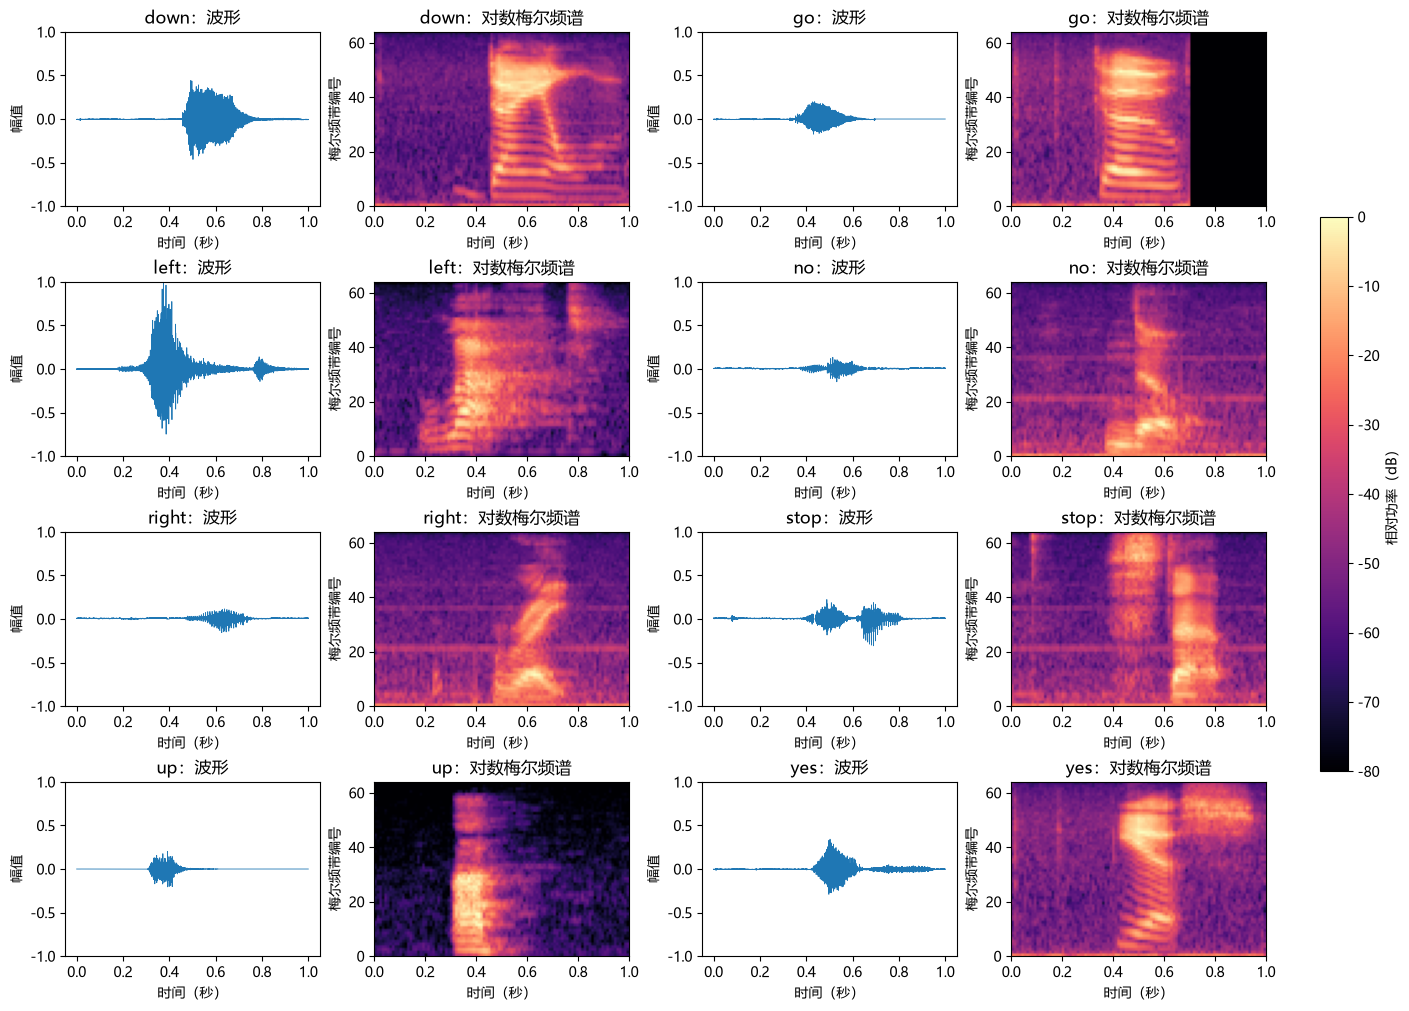

In [4]:
fig, axes = plt.subplots(4, 4, figsize=(14, 10), constrained_layout=True)
for label, name in enumerate(class_names):
    index = data_df[(data_df["label"] == label) & (data_df["split"] == "train")].index[0]
    row, col = divmod(label, 2)
    wave = read_audio(data_df.loc[index, "path"])
    ax = axes[row, col * 2]
    ax.plot(np.arange(len(wave)) / SAMPLE_RATE, wave, linewidth=0.6)
    ax.set_title(f"{name}：波形")
    ax.set_xlabel("时间（秒）")
    ax.set_ylabel("幅值")
    ax.set_ylim(-1, 1)
    ax = axes[row, col * 2 + 1]
    im = ax.imshow(mel_db[index].numpy(), origin="lower", aspect="auto", cmap="magma",
                   extent=[0, 1, 0, N_MELS], vmin=-80, vmax=0)
    ax.set_title(f"{name}：对数梅尔频谱")
    ax.set_xlabel("时间（秒）")
    ax.set_ylabel("梅尔频带编号")
fig.colorbar(im, ax=axes[:, 1::2].ravel().tolist(), shrink=0.6, label="相对功率（dB）")
fig.savefig(RESULT_DIR / "audio_mel_examples.png", dpi=180, bbox_inches="tight")
plt.show()

## 3. AlexNet 模型与训练参数

调用 torchvision 的 AlexNet，保留五层卷积的通道数 64、192、384、256、256，以及原有的 ReLU 和最大池化结构。首层改为单通道输入，自适应池化输出改为 2×2，全连接层调整为 1024→256→128→8，并使用 0.3 的 Dropout。这是适配小规模语音分类的 AlexNet，不是原版 ImageNet 分类头。

不加载图像预训练权重，全部参数从随机初始化开始训练。使用交叉熵、Adam 优化器、初始学习率 0.001、权重衰减 0.0001、批量大小 64，最多训练 20 轮。验证损失连续 2 轮没有改善时降低学习率，连续 5 轮没有改善时提前停止，按最低验证损失保存模型。

In [5]:
BATCH_SIZE, EPOCHS = 64, 20
LEARNING_RATE, WEIGHT_DECAY = 1e-3, 1e-4
generator = torch.Generator().manual_seed(SEED)
loaders = {}
for name, ids in split_ids.items():
    dataset = TensorDataset(features[ids], targets[ids])
    loaders[name] = DataLoader(dataset, batch_size=BATCH_SIZE, shuffle=(name == "train"),
                              num_workers=0, generator=generator if name == "train" else None)

model = alexnet(weights=None)
model.features[0] = nn.Conv2d(1, 64, kernel_size=11, stride=4, padding=2)
model.avgpool = nn.AdaptiveAvgPool2d((2, 2))
model.classifier = nn.Sequential(
    nn.Dropout(0.3), nn.Linear(256 * 2 * 2, 256), nn.ReLU(),
    nn.Dropout(0.3), nn.Linear(256, 128), nn.ReLU(), nn.Linear(128, len(class_names)))
model = model.to(device)
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=LEARNING_RATE, weight_decay=WEIGHT_DECAY)
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode="min", factor=0.5, patience=2)
print(model)
print("参数量：", sum(p.numel() for p in model.parameters()))
print("批量大小：", BATCH_SIZE, "最多轮数：", EPOCHS)

AlexNet(
  (features): Sequential(
    (0): Conv2d(1, 64, kernel_size=(11, 11), stride=(4, 4), padding=(2, 2))
    (1): ReLU(inplace=True)
    (2): MaxPool2d(kernel_size=3, stride=2, padding=0, dilation=1, ceil_mode=False)
    (3): Conv2d(64, 192, kernel_size=(5, 5), stride=(1, 1), padding=(2, 2))
    (4): ReLU(inplace=True)
    (5): MaxPool2d(kernel_size=3, stride=2, padding=0, dilation=1, ceil_mode=False)
    (6): Conv2d(192, 384, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (7): ReLU(inplace=True)
    (8): Conv2d(384, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (9): ReLU(inplace=True)
    (10): Conv2d(256, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (11): ReLU(inplace=True)
    (12): MaxPool2d(kernel_size=3, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (avgpool): AdaptiveAvgPool2d(output_size=(2, 2))
  (classifier): Sequential(
    (0): Dropout(p=0.3, inplace=False)
    (1): Linear(in_features=1024, out_features=256, bias=True)
  

In [6]:
def run_epoch(loader, training=False):
    model.train(training)
    total_loss = total_correct = total = 0
    with torch.set_grad_enabled(training):
        for x, y in loader:
            x, y = x.to(device), y.to(device)
            if training:
                optimizer.zero_grad(set_to_none=True)
            logits = model(x)
            loss = criterion(logits, y)
            if training:
                loss.backward()
                optimizer.step()
            total_loss += loss.item() * len(y)
            total_correct += (logits.argmax(1) == y).sum().item()
            total += len(y)
    return total_loss / total, total_correct / total

history = []
best_loss, best_epoch, wait = float("inf"), 0, 0
checkpoint = CACHE_DIR / "alexnet_keyword_best.pth"
for epoch in range(1, EPOCHS + 1):
    started = time.perf_counter()
    learning_rate = optimizer.param_groups[0]["lr"]
    train_loss, train_accuracy = run_epoch(loaders["train"], training=True)
    val_loss, val_accuracy = run_epoch(loaders["validation"])
    history.append({"epoch": epoch, "train_loss": train_loss, "val_loss": val_loss,
                    "train_accuracy": train_accuracy, "val_accuracy": val_accuracy,
                    "learning_rate": learning_rate})
    scheduler.step(val_loss)
    if val_loss < best_loss:
        best_loss, best_epoch, wait = val_loss, epoch, 0
        torch.save(model.state_dict(), checkpoint)
    else:
        wait += 1
    pd.DataFrame(history).to_csv(RESULT_DIR / "training_history.csv", index=False)
    print(f"Epoch {epoch:02d} | train loss {train_loss:.4f}, acc {train_accuracy:.1%} | "
          f"val loss {val_loss:.4f}, acc {val_accuracy:.1%} | "
          f"{time.perf_counter() - started:.1f}s", flush=True)
    if wait >= 5:
        print("验证损失连续 5 轮未改善，提前停止。")
        break

model.load_state_dict(torch.load(checkpoint, map_location=device, weights_only=True))
history_df = pd.DataFrame(history)
print("使用最低验证损失对应模型，epoch =", best_epoch)

Epoch 01 | train loss 2.0795, acc 12.7% | val loss 2.0761, acc 11.9% | 23.9s


Epoch 02 | train loss 2.0394, acc 16.6% | val loss 1.8773, acc 24.7% | 23.9s


Epoch 03 | train loss 1.5757, acc 36.7% | val loss 1.1029, acc 57.7% | 23.4s


Epoch 04 | train loss 0.9559, acc 61.8% | val loss 0.7372, acc 71.2% | 22.8s


Epoch 05 | train loss 0.7424, acc 70.2% | val loss 0.6928, acc 71.4% | 22.4s


...

Epoch 17 | train loss 0.1902, acc 93.4% | val loss 0.2777, acc 91.3% | 32.7s


Epoch 18 | train loss 0.1986, acc 93.2% | val loss 0.3321, acc 91.4% | 185.4s


Epoch 19 | train loss 0.1681, acc 94.2% | val loss 0.2576, acc 92.2% | 99.8s


Epoch 20 | train loss 0.1563, acc 94.7% | val loss 0.3096, acc 89.5% | 117.7s


使用最低验证损失对应模型，epoch = 19


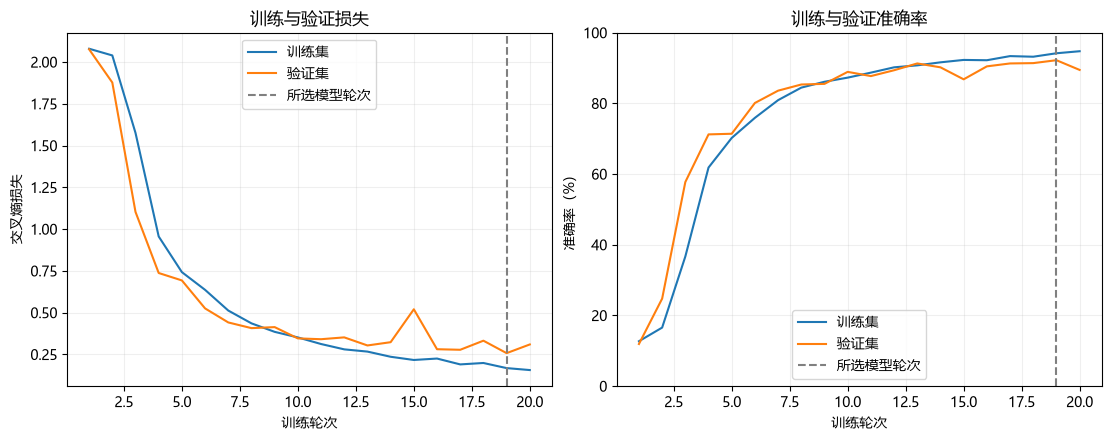

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.3), constrained_layout=True)
axes[0].plot(history_df["epoch"], history_df["train_loss"], label="训练集")
axes[0].plot(history_df["epoch"], history_df["val_loss"], label="验证集")
axes[0].set_ylabel("交叉熵损失")
axes[0].set_title("训练与验证损失")
axes[1].plot(history_df["epoch"], history_df["train_accuracy"] * 100, label="训练集")
axes[1].plot(history_df["epoch"], history_df["val_accuracy"] * 100, label="验证集")
axes[1].set_ylabel("准确率（%）")
axes[1].set_title("训练与验证准确率")
axes[1].set_ylim(0, 100)
for ax in axes:
    ax.axvline(best_epoch, color="gray", linestyle="--", label="所选模型轮次")
    ax.set_xlabel("训练轮次")
    ax.grid(alpha=0.2)
    ax.legend()
fig.savefig(RESULT_DIR / "training_curves.png", dpi=180, bbox_inches="tight")
plt.show()

## 4. 独立测试集评估

加载最低验证损失对应的模型，再对测试集进行一次最终评估。记录准确率、各类别精确率、召回率和 F1，并保存每条测试音频的预测。混淆矩阵的行是真实类别，列是预测类别，同时展示计数和按行归一化的结果。

In [8]:
model.eval()
all_logits = []
with torch.no_grad():
    for x, y in loaders["test"]:
        all_logits.append(model(x.to(device)).cpu())
test_logits = torch.cat(all_logits)
test_probabilities = test_logits.softmax(dim=1)
y_true = targets[test_ids].numpy()
y_pred = test_logits.argmax(1).numpy()
test_accuracy = accuracy_score(y_true, y_pred)
test_loss = criterion(test_logits, targets[test_ids]).item()
report = classification_report(y_true, y_pred, labels=np.arange(len(class_names)),
                               target_names=class_names, output_dict=True, zero_division=0)
report_df = pd.DataFrame(report).T
report_df.to_csv(RESULT_DIR / "classification_report.csv", encoding="utf-8-sig")
predictions_df = data_df.iloc[test_ids].copy()
predictions_df["predicted_class"] = [class_names[i] for i in y_pred]
predictions_df["confidence"] = test_probabilities.max(1).values.numpy()
predictions_df["correct"] = y_true == y_pred
predictions_df.to_csv(RESULT_DIR / "test_predictions.csv", index=False, encoding="utf-8-sig")
metrics = {"test_accuracy": float(test_accuracy), "test_loss": test_loss,
           "macro_f1": report["macro avg"]["f1-score"], "best_epoch": best_epoch,
           "epochs_run": len(history), "seed": SEED, "class_names": class_names,
           "split_sizes": {name: len(ids) for name, ids in split_ids.items()},
           "batch_size": BATCH_SIZE, "initial_learning_rate": LEARNING_RATE,
           "weight_decay": WEIGHT_DECAY, "train_mean_db": train_mean.item(),
           "train_std_db": train_std.item()}
(RESULT_DIR / "metrics.json").write_text(json.dumps(metrics, ensure_ascii=False, indent=2), encoding="utf-8")
print(f"测试准确率：{test_accuracy:.2%}，Macro F1：{metrics['macro_f1']:.4f}")
print(classification_report(y_true, y_pred, target_names=class_names, digits=4, zero_division=0))
report_df.loc[class_names]

测试准确率：91.77%，Macro F1：0.9182
              precision    recall  f1-score   support

        down     0.9603    0.9098    0.9344       133
          go     0.8788    0.8529    0.8657       170
        left     0.8476    0.9720    0.9055       143
          no     0.8777    0.8531    0.8652       143
       right     1.0000    0.9313    0.9644       160
        stop     0.9492    0.9106    0.9295       123
          up     0.8994    0.9346    0.9167       153
         yes     0.9494    0.9804    0.9646       153

    accuracy                         0.9177      1178
   macro avg     0.9203    0.9181    0.9182      1178
weighted avg     0.9197    0.9177    0.9178      1178



,precision,recall,f1-score,support
down,0.960317,0.909774,0.934363,133.0
go,0.878788,0.852941,0.865672,170.0
left,0.847561,0.972028,0.905537,143.0
no,0.877698,0.853147,0.865248,143.0
right,1.000000,0.931250,0.964401,160.0
stop,0.949153,0.910569,0.929461,123.0
up,0.899371,0.934641,0.916667,153.0
yes,0.949367,0.980392,0.964630,153.0


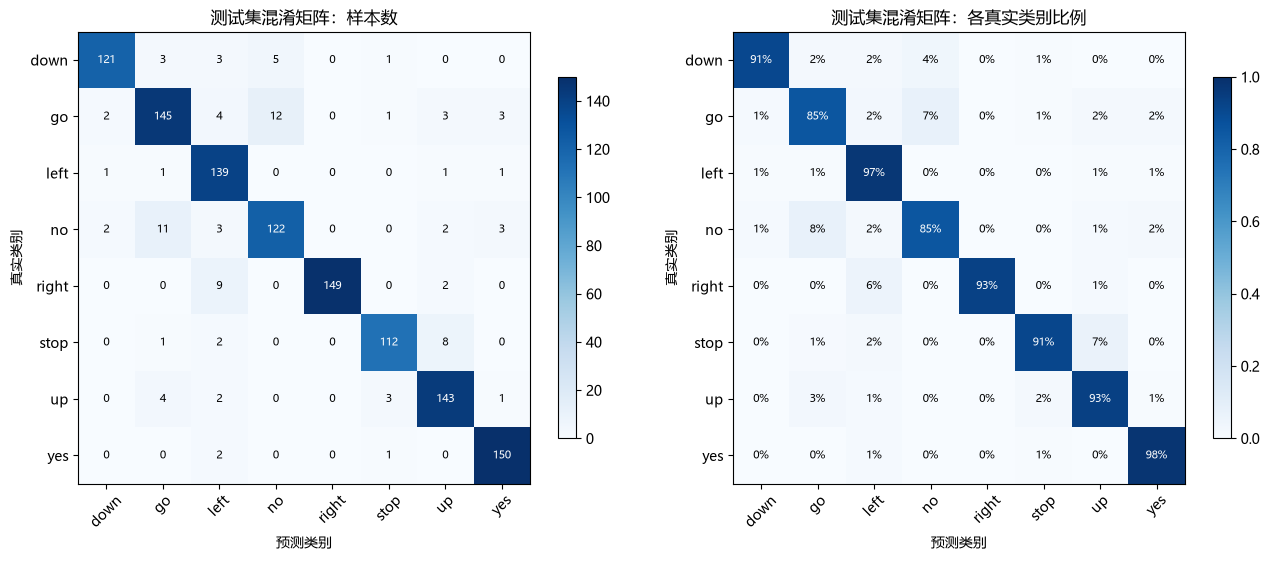

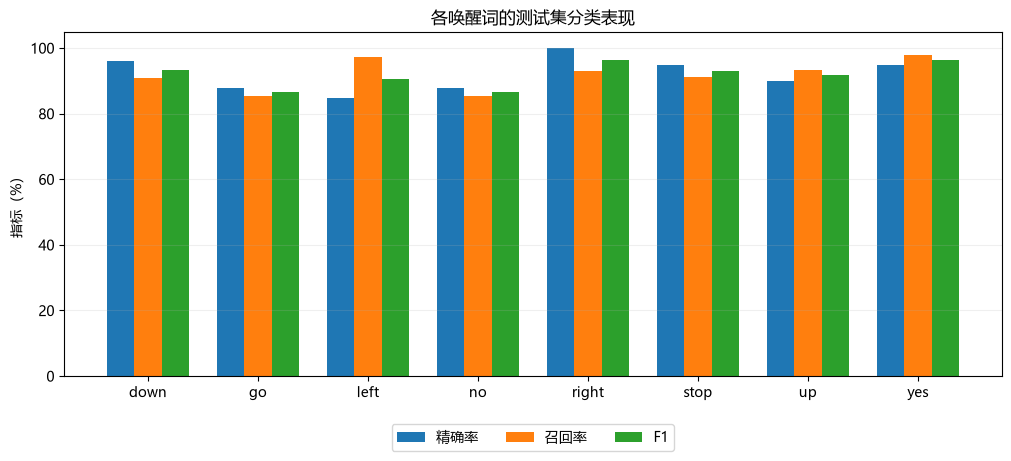

结果目录： E:\CODE\DeepLearning-exp\exp3\results\exp3D
最佳模型权重： E:\CODE\DeepLearning-exp\exp3\.cache\exp3D\alexnet_keyword_best.pth


In [9]:
cm = confusion_matrix(y_true, y_pred, labels=np.arange(len(class_names)))
cm_normalized = cm / np.maximum(cm.sum(axis=1, keepdims=True), 1)
pd.DataFrame(cm, index=class_names, columns=class_names).to_csv(
    RESULT_DIR / "confusion_matrix.csv", encoding="utf-8-sig")
fig, axes = plt.subplots(1, 2, figsize=(13, 5.5), constrained_layout=True)
for ax, values, title, normalized in [
    (axes[0], cm, "测试集混淆矩阵：样本数", False),
    (axes[1], cm_normalized, "测试集混淆矩阵：各真实类别比例", True),
]:
    im = ax.imshow(values, cmap="Blues", vmin=0, vmax=1 if normalized else max(1, cm.max()))
    for i in range(len(class_names)):
        for j in range(len(class_names)):
            text = f"{values[i, j]:.0%}" if normalized else str(values[i, j])
            ax.text(j, i, text, ha="center", va="center", fontsize=8,
                    color="white" if values[i, j] > values.max() * 0.55 else "black")
    ax.set_xticks(np.arange(len(class_names)), class_names, rotation=45)
    ax.set_yticks(np.arange(len(class_names)), class_names)
    ax.set_xlabel("预测类别")
    ax.set_ylabel("真实类别")
    ax.set_title(title)
    fig.colorbar(im, ax=ax, shrink=0.8)
fig.savefig(RESULT_DIR / "confusion_matrix.png", dpi=180, bbox_inches="tight")
plt.show()

fig, ax = plt.subplots(figsize=(10, 4.5), constrained_layout=True)
x = np.arange(len(class_names))
class_report = report_df.loc[class_names]
for offset, metric, title in [(-0.25, "precision", "精确率"), (0, "recall", "召回率"),
                              (0.25, "f1-score", "F1")]:
    ax.bar(x + offset, class_report[metric] * 100, width=0.25, label=title)
ax.set_xticks(x, class_names)
ax.set_ylim(0, 105)
ax.set_ylabel("指标（%）")
ax.set_title("各唤醒词的测试集分类表现")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.12), ncol=3)
ax.grid(axis="y", alpha=0.2)
fig.savefig(RESULT_DIR / "per_class_metrics.png", dpi=180, bbox_inches="tight")
plt.show()
print("结果目录：", RESULT_DIR)
print("最佳模型权重：", checkpoint)

## 结果分析提示

根据实际曲线判断收敛和训练、验证差距，根据混淆矩阵分析容易混淆的词。频谱可以把语音的时频变化表示为二维模式，使卷积网络利用局部结构学习分类；但实验只覆盖已知词的短音频，不能据此推断真实环境下的误唤醒率、未知词拒识、噪声鲁棒性或连续语音检测效果。